# Qiskit Fall Fest 2026 — PS-O1: Max-Cut on Weighted Graphs

This notebook implements a reproducible six-node weighted Max-Cut instance, a p=1 QAOA circuit, classical exhaustive search, unconstrained transpilation, Processor A/B topology checks, and a noisy Aer simulation for Processor B.

**Reproducibility:** graph seed 42, weight seed 42, transpiler seed 42, simulator seed 42, 4096 shots.

**Honesty note:** Processor A has five physical qubits and cannot host this six-qubit workload as specified. Routing overhead below reports changes in CX count and circuit depth as proxies; it does not claim an exact SWAP count.


In [10]:
%pip -q install qiskit qiskit-aer networkx matplotlib pandas


In [11]:
import json
import random
from pathlib import Path

import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, transpile
from qiskit.circuit import Parameter
from qiskit.transpiler import CouplingMap
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error, ReadoutError

SEED = 42
SHOTS = 4096
BASIS_GATES = ["rz", "sx", "x", "cx"]


## 1. Generate the six-node weighted graph and calculate the classical optimum

In [12]:
G = nx.erdos_renyi_graph(n=6, p=0.5, seed=SEED)
weight_rng = random.Random(SEED)
for u, v in G.edges():
    G[u][v]["weight"] = weight_rng.randint(1, 5)

print(f"Nodes: {G.number_of_nodes()}")
print(f"Edges: {G.number_of_edges()}")
print("Weighted edges:")
for u, v, data in G.edges(data=True):
    print(f"  ({u}, {v}) weight={data['weight']}")

def calculate_cut_from_bits(bits, graph):
    # bits is a node-indexed string: bits[i] is the assignment for node i.
    if len(bits) != graph.number_of_nodes():
        raise ValueError(f"Expected {graph.number_of_nodes()} bits, got {len(bits)}: {bits}")
    return sum(
        data["weight"]
        for u, v, data in graph.edges(data=True)
        if bits[u] != bits[v]
    )

def score_qiskit_bitstring(bitstring, graph):
    # Qiskit displays classical bit 0 at the rightmost end.
    bits = bitstring.replace(" ", "")[::-1]
    return calculate_cut_from_bits(bits, graph)

best_cut = -1
best_partition = None
for mask in range(1 << G.number_of_nodes()):
    bits = format(mask, f"0{G.number_of_nodes()}b")
    value = calculate_cut_from_bits(bits, G)
    if value > best_cut:
        best_cut = value
        best_partition = bits

print("\nClassical optimum:", best_cut)
print("One optimal node assignment (node order 0..5):", best_partition)


Nodes: 6
Edges: 9
Weighted edges:
  (0, 2) weight=1
  (0, 3) weight=1
  (0, 4) weight=3
  (1, 4) weight=2
  (1, 5) weight=2
  (2, 3) weight=2
  (2, 4) weight=1
  (3, 4) weight=5
  (3, 5) weight=1

Classical optimum: 16
One optimal node assignment (node order 0..5): 001011


## 2. Build the six-qubit QAOA p=1 circuit

In [13]:
%pip install pylatexenc

In [15]:
gamma = Parameter("gamma")
beta = Parameter("beta")
n = G.number_of_nodes()

qc = QuantumCircuit(n, n)
qc.h(range(n))
for u, v, data in G.edges(data=True):
    qc.rzz(2 * gamma * data["weight"], u, v)
for qubit in range(n):
    qc.rx(2 * beta, qubit)
qc.measure(range(n), range(n))

print("Graph nodes:", G.number_of_nodes())
print("Circuit qubits:", qc.num_qubits)
print("Classical bits:", qc.num_clbits)
assert G.number_of_nodes() == 6
assert qc.num_qubits == 6 and qc.num_clbits == 6
print(qc.draw(output="text"))


Graph nodes: 6
Circuit qubits: 6
Classical bits: 6
     ┌───┐                                          ┌────────────┐»
q_0: ┤ H ├─■─────────────■─────────────■────────────┤ Rx(2*beta) ├»
     ├───┤ │             │             │            └────────────┘»
q_1: ┤ H ├─┼─────────────┼─────────────┼──────────────────────────»
     ├───┤ │ZZ(2*gamma)  │             │                          »
q_2: ┤ H ├─■─────────────┼─────────────┼─────────────■────────────»
     ├───┤               │ZZ(2*gamma)  │             │ZZ(4*gamma) »
q_3: ┤ H ├───────────────■─────────────┼─────────────■────────────»
     ├───┤                             │ZZ(6*gamma)               »
q_4: ┤ H ├─────────────────────────────■──────────────────────────»
     ├───┤                                                        »
q_5: ┤ H ├────────────────────────────────────────────────────────»
     └───┘                                                        »
c: 6/════════════════════════════════════════════════════════════

## 3. Classical parameter sweep on the ideal simulator

,gamma,beta,shots,average_cut,best_observed_cut,classical_optimum,approximation_ratio
0,0.5,0.25,4096,9.502441,16,16,0.593903
1,1.0,0.50,4096,8.886475,16,16,0.555405
2,1.5,0.75,4096,8.527100,16,16,0.532944
3,2.0,1.00,4096,8.201904,16,16,0.512619


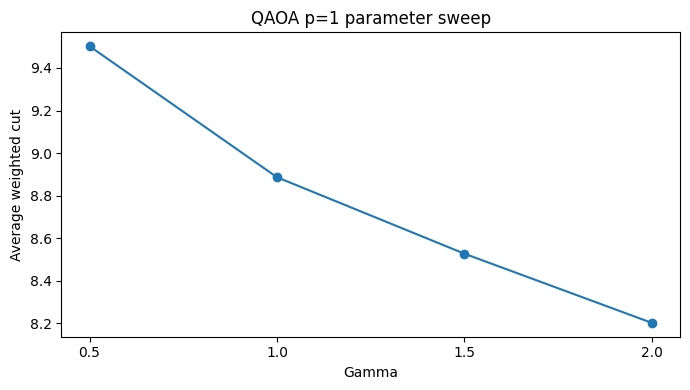

In [16]:
ideal_simulator = AerSimulator()
parameter_grid = [(0.5, 0.25), (1.0, 0.5), (1.5, 0.75), (2.0, 1.0)]
sweep_rows = []

for gamma_value, beta_value in parameter_grid:
    bound = qc.assign_parameters({gamma: gamma_value, beta: beta_value})
    compiled = transpile(bound, ideal_simulator, seed_transpiler=SEED)
    result = ideal_simulator.run(compiled, shots=SHOTS, seed_simulator=SEED).result()
    counts = result.get_counts(compiled)
    total = sum(counts.values())
    average = sum(score_qiskit_bitstring(key, G) * freq for key, freq in counts.items()) / total
    best = max(score_qiskit_bitstring(key, G) for key in counts)
    sweep_rows.append({
        "gamma": gamma_value,
        "beta": beta_value,
        "shots": total,
        "average_cut": average,
        "best_observed_cut": best,
        "classical_optimum": best_cut,
        "approximation_ratio": average / best_cut
    })

sweep_df = pd.DataFrame(sweep_rows)
display(sweep_df)
sweep_df.to_csv("qaoa_parameter_sweep.csv", index=False)

plt.figure(figsize=(7, 4))
plt.plot(sweep_df["gamma"].astype(str), sweep_df["average_cut"], marker="o")
plt.xlabel("Gamma")
plt.ylabel("Average weighted cut")
plt.title("QAOA p=1 parameter sweep")
plt.tight_layout()
plt.savefig("qaoa_parameter_sweep.png", dpi=160)
plt.show()


## 4. Transpile the same six-qubit circuit for the unconstrained baseline and Processor B

In [17]:
gamma_value, beta_value = 0.5, 0.25
bound_qc = qc.assign_parameters({gamma: gamma_value, beta: beta_value})

baseline = transpile(
    bound_qc,
    basis_gates=BASIS_GATES,
    optimization_level=1,
    seed_transpiler=SEED
)
print("Unconstrained baseline depth:", baseline.depth())
print("Unconstrained baseline operations:", dict(baseline.count_ops()))

processor_A_edges = [(0, 1), (1, 2), (2, 3), (3, 4)]
processor_B_edges = [
    (0,1), (1,2), (3,4), (4,5), (6,7), (7,8),
    (0,3), (3,6), (1,4), (4,7), (2,5), (5,8)
]

def make_coupling_map(undirected_edges):
    directed = undirected_edges + [(v, u) for u, v in undirected_edges]
    return CouplingMap(couplinglist=directed)

processor_A = make_coupling_map(processor_A_edges)
processor_B = make_coupling_map(processor_B_edges)

# Processor A cannot run this six-qubit circuit: fail clearly instead of inventing metrics.
processor_A_status = (
    "INFEASIBLE: six logical qubits required, five physical qubits available"
    if qc.num_qubits > processor_A.size()
    else "Feasible"
)
print("Processor A status:", processor_A_status)

transpiled_B = transpile(
    bound_qc,
    basis_gates=BASIS_GATES,
    coupling_map=processor_B,
    optimization_level=1,
    seed_transpiler=SEED
)
baseline_ops = baseline.count_ops()
b_ops = transpiled_B.count_ops()
routing_metrics = {
    "baseline_depth": baseline.depth(),
    "processor_B_depth": transpiled_B.depth(),
    "depth_delta": transpiled_B.depth() - baseline.depth(),
    "baseline_cx": int(baseline_ops.get("cx", 0)),
    "processor_B_cx": int(b_ops.get("cx", 0)),
    "cx_delta": int(b_ops.get("cx", 0) - baseline_ops.get("cx", 0)),
    "processor_B_physical_qubits": processor_B.size(),
    "processor_A_status": processor_A_status
}
print("Processor B depth:", transpiled_B.depth())
print("Processor B operations:", dict(b_ops))
print("Routing comparison:", routing_metrics)


Unconstrained baseline depth: 30
Unconstrained baseline operations: {'rz': 39, 'sx': 18, 'cx': 18, 'measure': 6}
Processor A status: INFEASIBLE: six logical qubits required, five physical qubits available
Processor B depth: 38
Processor B operations: {'rz': 39, 'cx': 24, 'sx': 18, 'measure': 6}
Routing comparison: {'baseline_depth': 30, 'processor_B_depth': 38, 'depth_delta': 8, 'baseline_cx': 18, 'processor_B_cx': 24, 'cx_delta': 6, 'processor_B_physical_qubits': 9, 'processor_A_status': 'INFEASIBLE: six logical qubits required, five physical qubits available'}


## 5. Noisy Processor B simulation

In [18]:
noise_model = NoiseModel()
single_qubit_error = depolarizing_error(0.001, 1)
cx_error = depolarizing_error(0.005, 2)
readout_error = ReadoutError([[0.99, 0.01], [0.01, 0.99]])

noise_model.add_all_qubit_quantum_error(single_qubit_error, ["rz", "sx", "x"])
noise_model.add_all_qubit_quantum_error(cx_error, ["cx"])
noise_model.add_all_qubit_readout_error(readout_error)

noisy_simulator = AerSimulator(noise_model=noise_model)
noisy_result = noisy_simulator.run(
    transpiled_B,
    shots=SHOTS,
    seed_simulator=SEED
).result()
noisy_counts = noisy_result.get_counts(transpiled_B)

total_shots = sum(noisy_counts.values())
average_noisy_cut = sum(
    score_qiskit_bitstring(bitstring, G) * frequency
    for bitstring, frequency in noisy_counts.items()
) / total_shots
best_noisy_cut = max(score_qiskit_bitstring(bitstring, G) for bitstring in noisy_counts)
approximation_ratio_noisy = average_noisy_cut / best_cut

noisy_metrics = {
    "processor": "Processor B",
    "shots": total_shots,
    "classical_optimum": best_cut,
    "average_noisy_cut": average_noisy_cut,
    "best_observed_cut": best_noisy_cut,
    "approximation_ratio": approximation_ratio_noisy,
    "circuit_depth": transpiled_B.depth(),
    "cx_gates": int(transpiled_B.count_ops().get("cx", 0)),
    "single_qubit_depolarizing": 0.001,
    "cx_depolarizing": 0.005,
    "readout_error": 0.01
}
display(pd.DataFrame([noisy_metrics]))
pd.DataFrame([noisy_metrics]).to_csv("noisy_results.csv", index=False)
pd.DataFrame([
    {"processor": "Unconstrained baseline", "physical_qubits": 6, "depth": baseline.depth(),
     "cx_gates": int(baseline_ops.get("cx", 0)), "status": "No connectivity constraint"},
    {"processor": "Processor A", "physical_qubits": 5, "depth": None, "cx_gates": None,
     "status": processor_A_status},
    {"processor": "Processor B", "physical_qubits": 9, "depth": transpiled_B.depth(),
     "cx_gates": int(b_ops.get("cx", 0)), "status": "Transpilation succeeded"}
]).to_csv("processor_comparison.csv", index=False)

print("Total noisy shots:", total_shots)
print("Average noisy cut:", round(average_noisy_cut, 4))
print("Best observed noisy cut:", best_noisy_cut)
print("Noisy approximation ratio:", round(approximation_ratio_noisy, 4))


,processor,shots,classical_optimum,average_noisy_cut,best_observed_cut,approximation_ratio,circuit_depth,cx_gates,single_qubit_depolarizing,cx_depolarizing,readout_error
0,Processor B,4096,16,9.438965,16,0.589935,38,24,0.001,0.005,0.01


Total noisy shots: 4096
Average noisy cut: 9.439
Best observed noisy cut: 16
Noisy approximation ratio: 0.5899


## 6. Plot the weighted graph and processor comparison

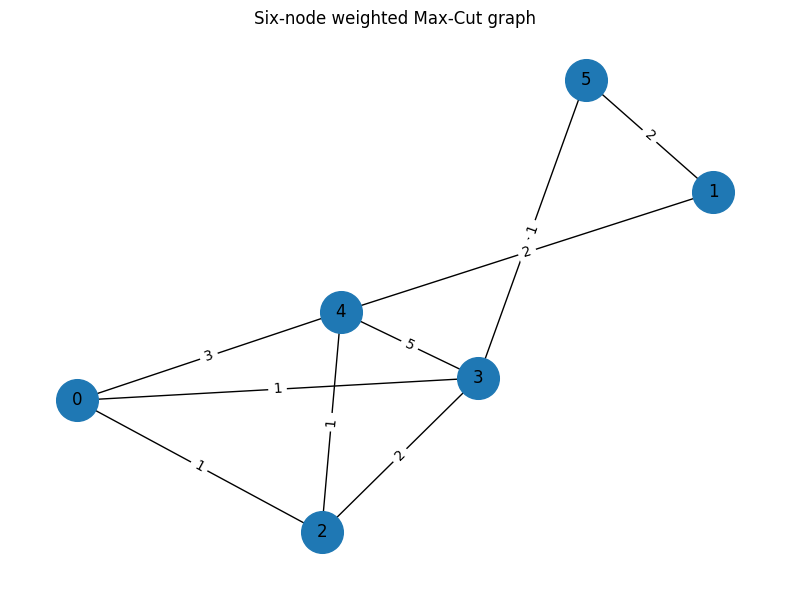

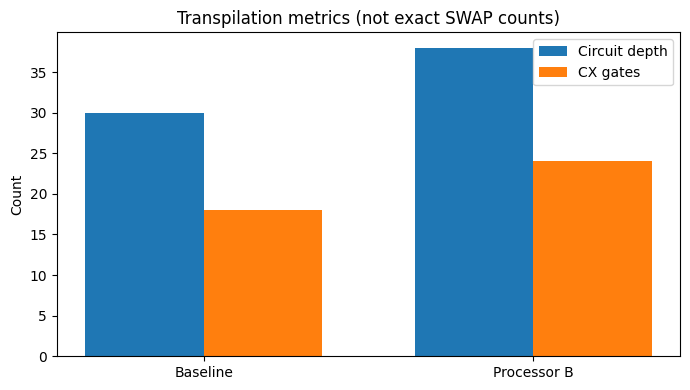

In [19]:
pos = nx.spring_layout(G, seed=SEED)
plt.figure(figsize=(8, 6))
nx.draw_networkx(G, pos, with_labels=True, node_size=900)
nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "weight"))
plt.title("Six-node weighted Max-Cut graph")
plt.axis("off")
plt.tight_layout()
plt.savefig("weighted_graph.png", dpi=160)
plt.show()

labels = ["Baseline", "Processor B"]
depths = [baseline.depth(), transpiled_B.depth()]
cx_counts = [int(baseline_ops.get("cx", 0)), int(b_ops.get("cx", 0))]
x = np.arange(len(labels))
plt.figure(figsize=(7, 4))
plt.bar(x - 0.18, depths, width=0.36, label="Circuit depth")
plt.bar(x + 0.18, cx_counts, width=0.36, label="CX gates")
plt.xticks(x, labels)
plt.ylabel("Count")
plt.title("Transpilation metrics (not exact SWAP counts)")
plt.legend()
plt.tight_layout()
plt.savefig("processor_B_metrics.png", dpi=160)
plt.show()


## 7. Interpretation and limitations

- The exhaustive-search optimum is computed from the generated weighted graph during execution.
- Processor A is explicitly infeasible for the six-qubit workload because it has only five physical qubits.
- Processor B's noisy cut metrics are computed from the newly executed noisy simulation, not hard-coded.
- Differences in CX count and circuit depth are routing-overhead proxies, **not exact SWAP counts**.
- Noise rates are simulation assumptions, not hardware calibration measurements.
- This small simulation does not establish quantum advantage.

Files generated by running this notebook: `qaoa_parameter_sweep.csv`, `qaoa_parameter_sweep.png`, `noisy_results.csv`, `processor_comparison.csv`, `weighted_graph.png`, and `processor_B_metrics.png`.
